## Lab 2: Principal Component Analysis

You can use external libraries for linear algebra operations (e.g. `numpy.linalg`) but you are expected to write your own PCA algorithm.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OrdinalEncoder

np.random.seed(42)

# Exercise 1
Use the `Dry_Bean_Dataset.xlsx` available on the github page of the labs.
- Divide your dataset into a train and a test set.
- Preprocess the data by centering the variables and dividing them by their standard deviation (statistics computed on the **training set only**, then reused on the test set).

In [13]:
df = pd.read_excel("../Datasets/Dry_Bean_Dataset.xlsx")
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
y = OrdinalEncoder().fit_transform(df[['Class']]).ravel()
print(y.shape, np.unique(y))
classes = sorted(df['Class'].unique())
print(classes)
X = df.drop('Class', axis=1).to_numpy(dtype=float)
print(X.shape, classes)

(13611,) [0. 1. 2. 3. 4. 5. 6.]
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
(13611, 16) ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [5]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_mean = Xtrain.mean(axis=0)
X_std = Xtrain.std(axis=0, ddof=1)

Xtrain = (Xtrain - X_mean) / X_std
Xtest = (Xtest - X_mean) / X_std   # same transformation as the training set (no information from the test set)

- Write your own algorithm to perform PCA on the variables.

In [ ]:
class MyPCA:
    """PCA via eigendecomposition of the covariance matrix."""
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        C = Xc.T @ Xc / (X.shape[0] - 1)           # covariance matrix (unbiased)
        eigval, eigvec = np.linalg.eigh(C)         # eigh: symmetric matrix, ascending eigenvalues
        order = np.argsort(eigval)[::-1]           # sort by decreasing eigenvalue
        self.eigenvalues_ = eigval[order]
        self.components_ = eigvec[:, order]        # columns = principal directions
        self.explained_variance_ratio_ = self.eigenvalues_ / self.eigenvalues_.sum()
        return self

    def transform(self, X, k=None):
        Z = (X - self.mean_) @ self.components_
        return Z if k is None else Z[:, :k]

    def inverse_transform(self, Z):
        k = Z.shape[1]
        return Z @ self.components_[:, :k].T + self.mean_

pca = MyPCA().fit(Xtrain)

In [11]:
# sanity check against sklearn
from sklearn.decomposition import PCA
sk = PCA().fit(Xtrain)
print("eigenvalues match:", np.allclose(pca.eigenvalues_, sk.explained_variance_))
# directions are defined up to a sign
print("components match (up to sign):", np.allclose(np.abs(pca.components_.T), np.abs(sk.components_)))

eigenvalues match: True
components match (up to sign): True


- Using the training set, obtain and plot the eigenvalue spectrum using the log-scale for the y-axis. Plot also the cumulative fraction of explained variance. What number of principal components would you select?

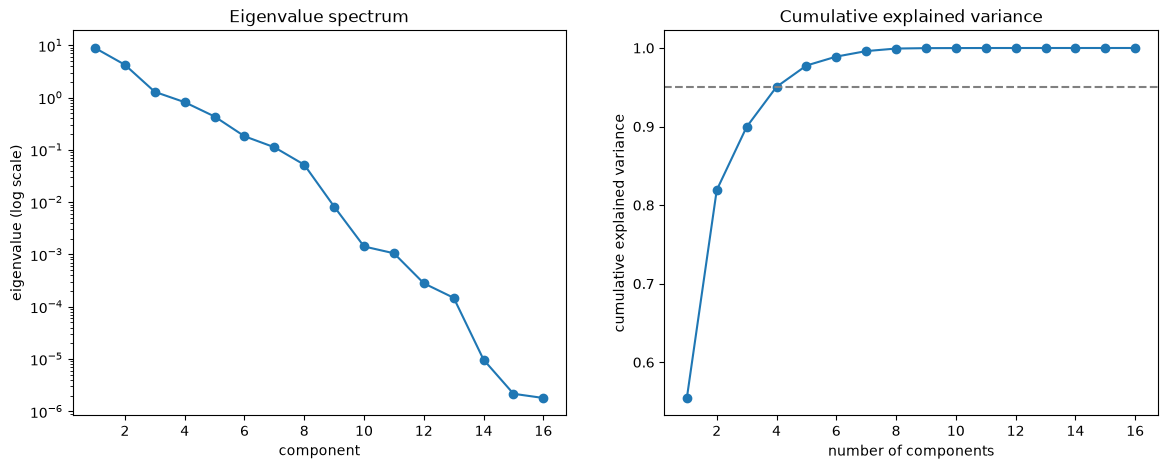

1 0.5545
2 0.8192
3 0.8996
4 0.9505
5 0.9777
6 0.9891
7 0.9961


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].semilogy(np.arange(1, 17), pca.eigenvalues_, "o-")
ax[0].set_xlabel("component"); ax[0].set_ylabel("eigenvalue (log scale)")
ax[0].set_title("Eigenvalue spectrum")

cum = np.cumsum(pca.explained_variance_ratio_)
ax[1].plot(np.arange(1, 17), cum, "o-")
ax[1].axhline(0.95, color="gray", ls="--")
ax[1].set_xlabel("number of components"); ax[1].set_ylabel("cumulative explained variance")
ax[1].set_title("Cumulative explained variance")
plt.show()

for k in range(1, 8):
    print(k, round(cum[k-1], 4))

The spectrum drops sharply after the first components (the variables are strongly correlated: area, perimeter, axis lengths, ... describe the same size of the bean). The first 2 PCs explain ~82% of the variance, **4 PCs reach 95%** and 6 PCs reach ~99%. A reasonable choice is therefore **4-6 components** (elbow of the spectrum / 95-99% of explained variance), far fewer than the 16 original variables.

- Project the data (training set) in the first two principal components and color by class. Do it also for the three principal components.

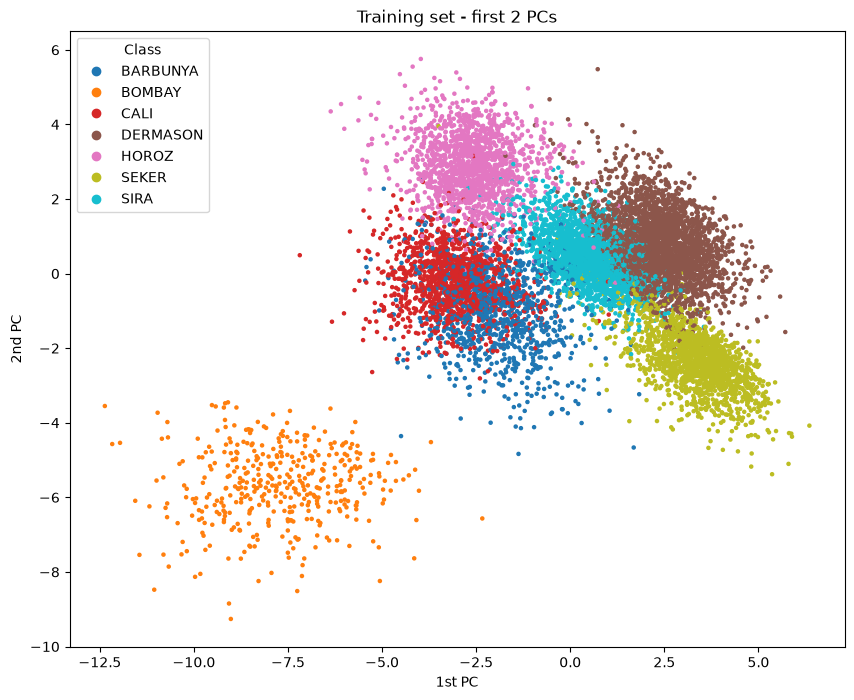

In [8]:
Ztrain = pca.transform(Xtrain)

plt.figure(figsize=(10, 8))
sc = plt.scatter(Ztrain[:, 0], Ztrain[:, 1], c=ytrain, s=5, cmap="tab10")
plt.legend(handles=sc.legend_elements()[0], labels=classes, title="Class")
plt.xlabel("1st PC"); plt.ylabel("2nd PC")
plt.title("Training set - first 2 PCs")
plt.show()

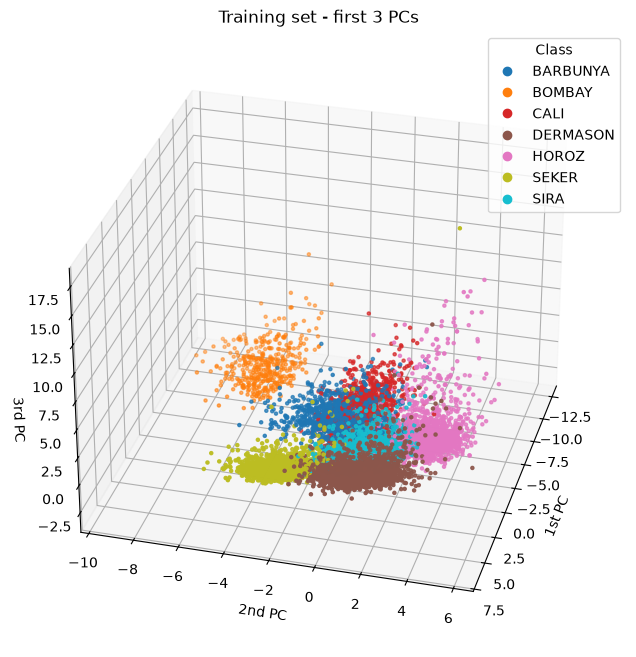

In [9]:
plt.figure(figsize=(10, 8))
axes = plt.axes(projection='3d')
sc = axes.scatter3D(Ztrain[:, 0], Ztrain[:, 1], Ztrain[:, 2], c=ytrain, s=5, cmap="tab10")
axes.legend(handles=sc.legend_elements()[0], labels=classes, title="Class")
axes.set_xlabel('1st PC'); axes.set_ylabel('2nd PC'); axes.set_zlabel('3rd PC')
axes.view_init(30, 15)
plt.title("Training set - first 3 PCs")
plt.show()

- For an increasing number of principal components (1 to 16):
  - Apply a multinomial logistic regression to learn a model on the training set (use `sklearn.linear_model.LogisticRegression`).
  - Transform the test set with the matrix learned from the training set. Make a prediction with the logistic model learned.
  - Assess the quality of the predictions and comment on the results.

In [10]:
Ztest = pca.transform(Xtest)

score = []
for k in range(1, 17):
    lr = LogisticRegression(max_iter=2000)   # multinomial by default for >2 classes
    lr.fit(Ztrain[:, :k], ytrain)
    acc = lr.score(Ztest[:, :k], ytest)
    score.append(acc)
    print(f"{k:2d} PCs: test accuracy = {acc:.4f}")

 1 PCs: test accuracy = 0.6405
 2 PCs: test accuracy = 0.8729
 3 PCs: test accuracy = 0.8777
 4 PCs: test accuracy = 0.8873
 5 PCs: test accuracy = 0.9199
 6 PCs: test accuracy = 0.9203
 7 PCs: test accuracy = 0.9207
 8 PCs: test accuracy = 0.9210
 9 PCs: test accuracy = 0.9207
10 PCs: test accuracy = 0.9210
11 PCs: test accuracy = 0.9210
12 PCs: test accuracy = 0.9210
13 PCs: test accuracy = 0.9218
14 PCs: test accuracy = 0.9214
15 PCs: test accuracy = 0.9214
16 PCs: test accuracy = 0.9214


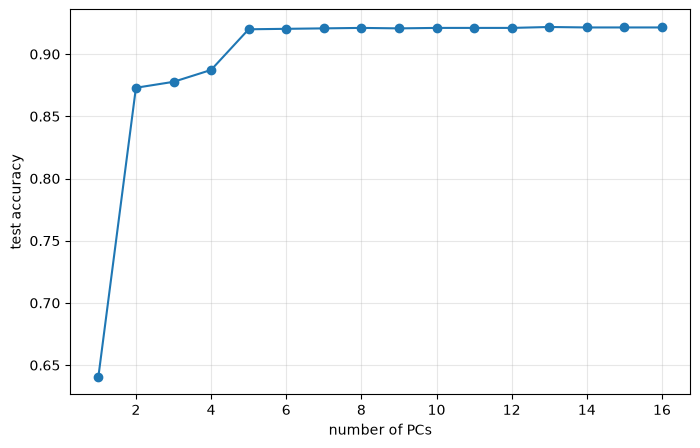

Maximum accuracy 0.9218 reached with 13 PCs


In [11]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 17), score, "o-")
plt.xlabel("number of PCs"); plt.ylabel("test accuracy")
plt.grid(alpha=0.3)
plt.show()

best = int(np.argmax(score)) + 1
print(f"Maximum accuracy {np.max(score):.4f} reached with {best} PCs")

**Comment.** With 1 PC the accuracy is only ~64%; it jumps to ~87% with 2 PCs and to ~92% with 5 PCs, then **saturates** (~0.921 for 5-16 PCs, the maximum being reached with 13 PCs but with differences of the order of 0.001, i.e. noise). The remaining components carry very little variance and no additional information for a linear classifier. With 5 PCs we obtain practically the same accuracy as with the 16 original variables: PCA gives a large compression with almost no loss for this task. (The remaining errors are mostly between similar classes, e.g. DERMASON/SIRA and BARBUNYA/CALI.)

# Exercise 2
Apply PCA to the Swiss Roll dataset ($n=1000$) from Lab 1 and plot the projection on the first two principal components. Color the points by the position $\phi$ along the roll and comment on your results.

In [12]:
def swiss_roll(n):
    """
    Parameters:
    n: int
        Number of points to generate"""
    data = np.zeros((n, 3))
    phi = np.random.uniform(low=1.5*np.pi, high=4.5*np.pi, size=n)
    psi = np.random.uniform(0, 10, n)

    data[:, 0] = phi*np.cos(phi)  # x coordinate
    data[:, 1] = phi*np.sin(phi)  # y coordinate
    data[:, 2] = psi              # z coordinate
    return data, phi

Xs, phi = swiss_roll(1000)

explained variance ratio: [0.524 0.391 0.086]


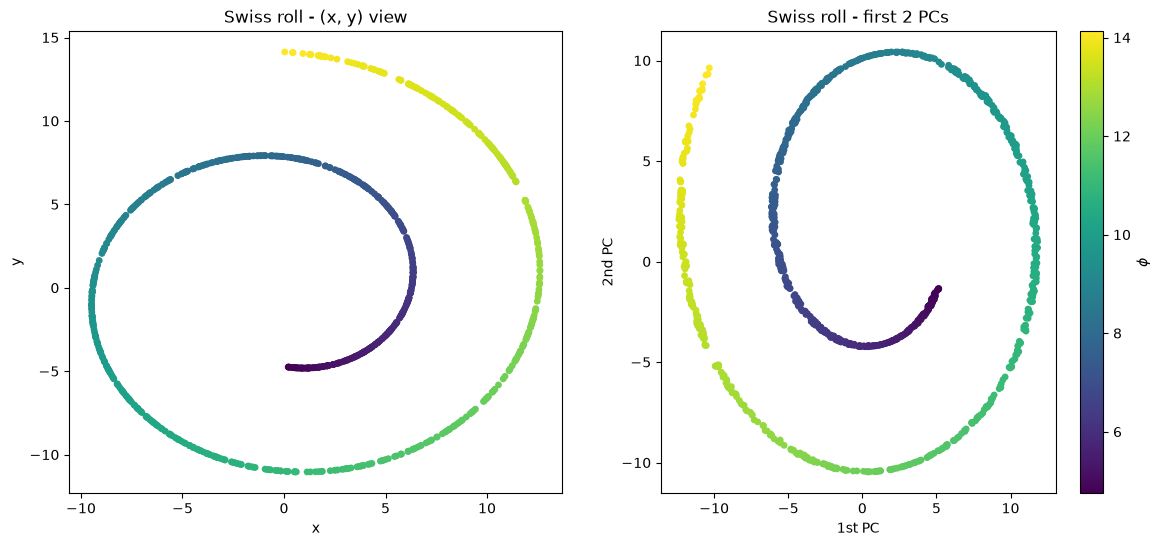

In [13]:
pca_swiss = MyPCA().fit(Xs)
Zs = pca_swiss.transform(Xs, k=2)
print("explained variance ratio:", pca_swiss.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].scatter(Xs[:, 0], Xs[:, 1], c=phi, s=15, cmap="viridis")
ax[0].set_title("Swiss roll - (x, y) view"); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
sc = ax[1].scatter(Zs[:, 0], Zs[:, 1], c=phi, s=15, cmap="viridis")
ax[1].set_title("Swiss roll - first 2 PCs"); ax[1].set_xlabel("1st PC"); ax[1].set_ylabel("2nd PC")
plt.colorbar(sc, ax=ax[1], label=r"$\phi$")
plt.show()

**Comment.** PCA is a *linear* projection: it only rotates the axes and keeps the directions of maximal variance. Here the first two PCs (~92% of the variance) essentially coincide with the $(x,y)$ plane, so the result is the **rolled-up spiral itself**: PCA does *not* unroll the manifold. The colour ($\phi$) varies smoothly along the spiral, but the two intrinsic coordinates of the sheet ($\phi$ and $\psi$, the position along the roll and along its width) are not recovered: $\psi$ is lost (it sits in the 3rd PC, which has little variance) and distances along the spiral are not preserved (points on adjacent turns are close in the projection although they are far apart on the manifold). This motivates the nonlinear methods of the next labs (Isomap, Kernel PCA).

## Bonus: reconstruction error
Reconstruction error on the test set as a function of the number of PCs, compared with the eigenvalues.

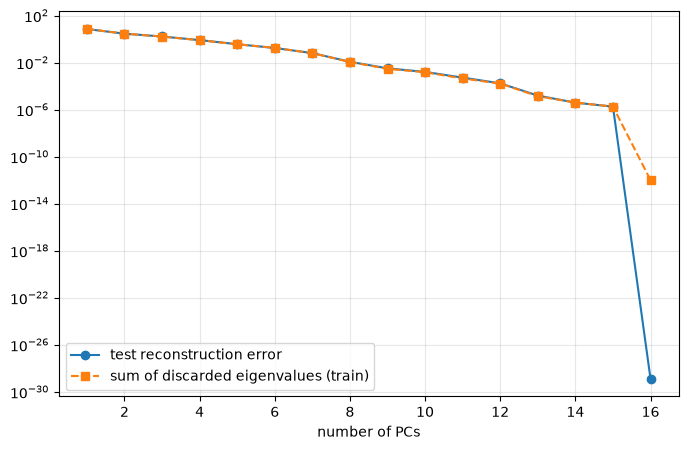

In [14]:
err = []
for k in range(1, 17):
    Xhat = pca.inverse_transform(Ztest[:, :k])
    # Xtest is already centered with the *training* mean; pca.mean_ is ~0, so inverse_transform is consistent
    err.append(np.mean(np.sum((Xtest - Xhat)**2, axis=1)))

# expected error on the training data = sum of the discarded eigenvalues
expected = [pca.eigenvalues_[k:].sum() for k in range(1, 17)]

plt.figure(figsize=(8, 5))
plt.semilogy(range(1, 17), err, "o-", label="test reconstruction error")
plt.semilogy(range(1, 17), np.maximum(expected, 1e-12), "s--", label="sum of discarded eigenvalues (train)")
plt.xlabel("number of PCs"); plt.legend(); plt.grid(alpha=0.3)
plt.show()